# Tarea 5: Diseñar una CNN compacta con Global Average Pooling

El objetivo de esta tarea es diseñar una CNN con Global Average Pooling (GAP) que supere 95 % de exactitud en validación en MNIST con menos de 54 330 parámetros entrenables, el total de la CNN base con Flatten. Entre las arquitecturas que cumplan ambos requisitos se elige la de menos parámetros. Después se mide qué tan bien reconoce los dígitos cuando cambia su posición.

# Datos y modelos de referencia

Usamos las mismas particiones estratificadas de MNIST del notebook de clase (8 000 de entrenamiento, 1 500 de validación y 2 000 de prueba) y el mismo margen negro de cuatro píxeles. La forma que recibe la red es 36 × 36 × 1.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import train_test_split
from tensorflow import keras

In [3]:
SEMILLA = 42
N_ENT, N_VAL, N_PRUEBA = 8000, 1500, 2000
MARGEN = 4

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()
i_ent, i_val = train_test_split(
    np.arange(len(y_des)), train_size=N_ENT, test_size=N_VAL,
    stratify=y_des, random_state=SEMILLA,
)
i_prueba, _ = train_test_split(
    np.arange(len(y_test)), train_size=N_PRUEBA, stratify=y_test,
    random_state=SEMILLA,
)

def preparar_imagenes(imagenes):
    imagenes = np.pad(imagenes, ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN)))
    return imagenes[..., None].astype(np.float32) / 255.0

X_ent, y_ent = preparar_imagenes(x_des[i_ent]), y_des[i_ent]
X_val, y_val = preparar_imagenes(x_des[i_val]), y_des[i_val]
X_prueba, y_prueba = preparar_imagenes(x_test[i_prueba]), y_test[i_prueba]
FORMA = X_ent.shape[1:]
for nombre, X in [("Entrenamiento", X_ent), ("Validación", X_val), ("Prueba", X_prueba)]:
    print(f"{nombre}: {X.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Entrenamiento: (8000, 36, 36, 1)
Validación: (1500, 36, 36, 1)
Prueba: (2000, 36, 36, 1)


Reutilizamos la configuración de entrenamiento del notebook (Adam, tasa 0.001, lote 128, 20 épocas, semilla 42), las funciones entrenar, desplazar y predecir, y el constructor crear_cnn. Con este constructor volvemos a entrenar los dos modelos de referencia: la CNN + Flatten y la CNN + GAP base. Ambas tienen dos convoluciones de 16 filtros 3 × 3 y un max pooling al final.

In [4]:
CAPAS = (16, 16)
LOTE = 128
EPOCAS = 20
TASA = 0.001

def crear_cnn(filtros=CAPAS, padding="same", pooling="max", stride=1, cabeza="flatten"):
    capas = [keras.Input(shape=FORMA)]
    for i, n_filtros in enumerate(filtros):
        capas.append(keras.layers.Conv2D(
            n_filtros, 3, strides=stride if i == 0 else 1,
            padding=padding, activation="relu", name=f"conv_{i + 1}",
        ))
    if pooling == "max":
        capas.append(keras.layers.MaxPooling2D(2, name="pool"))
    elif pooling == "average":
        capas.append(keras.layers.AveragePooling2D(2, name="pool"))
    elif pooling != "sin":
        raise ValueError("pooling debe ser 'max', 'average' o 'sin'")

    if cabeza == "flatten":
        capas.append(keras.layers.Flatten(name="vector"))
    elif cabeza == "gap":
        capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    else:
        raise ValueError("cabeza debe ser 'flatten' o 'gap'")

    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas, name=f"cnn_{cabeza}")

def lotes(X, y=None, mezclar=False):
    datos = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if mezclar:
        datos = datos.shuffle(len(X), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return datos.batch(LOTE).with_options(opciones).prefetch(1)

def entrenar(constructor, **configuracion):
    keras.utils.set_random_seed(SEMILLA)
    modelo = constructor(**configuracion)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    historial = modelo.fit(
        lotes(X_ent, y_ent, mezclar=True),
        validation_data=lotes(X_val, y_val),
        epochs=EPOCAS, verbose=0, shuffle=False, 
    ).history
    return modelo, historial

def curvas(ax, historial, metrica, etiqueta, color, estilo="-"):
    valores = historial[metrica]
    ax.plot(range(1, len(valores) + 1), valores, estilo, marker="o",
            label=etiqueta, color=color)

def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Usa un desplazamiento dentro del margen de la imagen.")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado

def predecir(modelo, imagenes):
    return modelo.predict(lotes(imagenes), verbose=0).argmax(axis=1)

modelo_cnn, hist_cnn = entrenar(crear_cnn, cabeza="flatten")
modelo_gap, hist_gap = entrenar(crear_cnn, cabeza="gap")

La tabla resume los modelos de referencia en esta ejecución.

En CPU, TensorFlow no es totalmente determinista, así que el GAP base puede diferir unas décimas de la ejecución guardada del profesor (44.07 % en validación). Flatten se reproduce igual: 96.87 %.

In [5]:
def parametros_entrenables(modelo):
    return sum(int(np.prod(v.shape)) for v in modelo.trainable_weights)

def exactitud(modelo, imagenes, etiquetas):
    return 100 * np.mean(predecir(modelo, imagenes) == etiquetas)

def exactitud_desplazada(modelo, distancia):
    if distancia == 0:
        return exactitud(modelo, X_prueba, y_prueba)
    direcciones = ((-distancia, 0), (distancia, 0), (0, -distancia), (0, distancia))  
    return float(np.mean([exactitud(modelo, desplazar(X_prueba, dy, dx), y_prueba)
                          for dy, dx in direcciones]))

referencia = pd.DataFrame([
    {"Modelo base": nombre,
     "Parámetros entrenables": parametros_entrenables(modelo),
     "Exactitud de validación (%)": 100 * historial["val_accuracy"][-1],
     "Prueba a 0 px (%)": exactitud_desplazada(modelo, 0),
     "Prueba a 4 px (%)": exactitud_desplazada(modelo, 4)}
    for nombre, modelo, historial in [("CNN + Flatten", modelo_cnn, hist_cnn),
                                      ("CNN + GAP", modelo_gap, hist_gap)]
])
LIMITE_PARAMETROS = int(referencia.loc[0, "Parámetros entrenables"])
display(referencia.round(2))

,Modelo base,Parámetros entrenables,Exactitud de validación (%),Prueba a 0 px (%),Prueba a 4 px (%)
0,CNN + Flatten,54330,96.87,97.05,37.30
1,CNN + GAP,2650,44.20,46.20,46.21


# Explorar arquitecturas con GAP

**Diagnóstico del GAP base.** Sus dos convoluciones de 3 × 3 sin pooling intermedio solo «ven» una ventana de 5 × 5 píxeles (campo receptivo). El max pooling final apenas lo lleva a 6 × 6. Cada uno de los 16 canales detecta un trazo local, y GAP promedia esa respuesta sobre toda la imagen de 36 × 36. El vector final dice cuánto de cada trazo hay, pero no cómo se combinan. Un 6 y un 9, o un 2 y un 5, tienen trazos locales muy parecidos.

Con GAP, la red tiene que codificar la forma completa del dígito dentro de los canales, antes de promediar. Eso exige un campo receptivo del tamaño del dígito (≈ 20 píxeles). Lo más barato es intercalar pooling entre convoluciones: cada pooling duplica el alcance de las convoluciones siguientes sin añadir pesos.

Definimos un constructor flexible. La arquitectura se escribe como una secuencia: un número es una convolución con esos filtros (padding same, ReLU) y "P" es un max pooling 2 × 2. La cabeza siempre es GlobalAveragePooling2D + Dense(10). Todas las variantes usan la misma función entrenar, es decir, la misma semilla, las mismas particiones y 20 épocas.

| Variante | Arquitectura | Kernel | Qué se prueba |
|---|---|---|---|
| A · GAP base | 16-16-P | 3 | Referencia (idéntica a crear_cnn(cabeza="gap")) |
| B · Pooling intermedio | 16-P-16 | 3 | **Solo** mueve el pooling respecto a A (mismos parámetros) |
| C · Más profundidad | 16-16-16-P | 3 | **Solo** añade una convolución respecto a A |
| D · Más filtros | 32-32-P | 3 | **Solo** duplica los filtros respecto a A |
| E · 2 bloques | 16-P-32-P | 3 | Dos bloques conv + pool |
| F · 3 bloques mini | 4-P-8-P-16-P | 3 | Tres bloques muy estrechos |
| G · 3 bloques pequeños | 8-P-16-P-16-P | 3 | Tres bloques, último con 16 filtros |
| H · 3 bloques | 8-P-16-P-32-P | 3 | Tres bloques, ancho creciente |
| I · 3 bloques, kernel 5 | 8-P-16-P-32-P | 5 | **Solo** cambia el kernel respecto a H |
| J · 3 bloques anchos | 16-P-32-P-64-P | 3 | **Solo** duplica los filtros respecto a H |
| K · 3 bloques, final 32 | 16-P-32-P-32-P | 3 | **Solo** reduce la última capa de J a 32 filtros |
| L · 3 bloques + conv final | 8-P-16-P-32-P-32 | 3 | **Solo** añade una convolución tras el último pooling de H |

Las comparaciones de una sola decisión son A→B (ubicación del pooling), A→C (profundidad), A→D (ancho), H→I (tamaño del kernel) H→J (ancho en la red de tres bloques), J→K (filtros de la última capa) y H→L (profundidad después del último pooling). F, G y H forman además una escalera de ancho.

In [6]:
def crear_cnn_gap(arquitectura, kernel=3):
    capas = [keras.Input(shape=FORMA)]
    n_conv = n_pool = 0
    for paso in arquitectura:
        if paso == "P":
            n_pool += 1
            capas.append(keras.layers.MaxPooling2D(2, name=f"pool_{n_pool}"))
        else:
            n_conv += 1
            capas.append(keras.layers.Conv2D(paso, kernel, padding="same",
                                             activation="relu", name=f"conv_{n_conv}"))
    capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas, name="cnn_gap")

def campo_receptivo(arquitectura, kernel=3):
    campo, salto = 1, 1
    for paso in arquitectura:
        if paso == "P":
            campo += salto
            salto *= 2
        else:
            campo += (kernel - 1) * salto
    return campo

variantes_gap = {
    "A · GAP base":            {"arquitectura": (16, 16, "P")},
    "B · Pooling intermedio":  {"arquitectura": (16, "P", 16)},
    "C · Más profundidad":     {"arquitectura": (16, 16, 16, "P")},
    "D · Más filtros":         {"arquitectura": (32, 32, "P")},
    "E · 2 bloques":           {"arquitectura": (16, "P", 32, "P")},
    "F · 3 bloques mini":      {"arquitectura": (4, "P", 8, "P", 16, "P")},
    "G · 3 bloques pequeños":  {"arquitectura": (8, "P", 16, "P", 16, "P")},
    "H · 3 bloques":           {"arquitectura": (8, "P", 16, "P", 32, "P")},
    "I · 3 bloques, kernel 5": {"arquitectura": (8, "P", 16, "P", 32, "P"), "kernel": 5},
    "J · 3 bloques anchos":    {"arquitectura": (16, "P", 32, "P", 64, "P")},
    "K · 3 bloques, final 32": {"arquitectura": (16, "P", 32, "P", 32, "P")},
    "L · 3 bloques + conv final": {"arquitectura": (8, "P", 16, "P", 32, "P", 32)},
}

modelos_gap, historiales_gap, filas = {}, {}, []
for nombre, config in variantes_gap.items():
    modelo, historial = entrenar(crear_cnn_gap, **config)
    modelos_gap[nombre], historiales_gap[nombre] = modelo, historial
    forma = modelo.get_layer("vector").input.shape[1:]
    filas.append({
        "Variante": nombre,
        "Arquitectura": "-".join(str(p) for p in config["arquitectura"]),
        "Kernel": config.get("kernel", 3),
        "Campo receptivo (px)": campo_receptivo(config["arquitectura"], config.get("kernel", 3)),
        "Mapas antes de GAP": " × ".join(str(d) for d in forma),
        "Parámetros entrenables": parametros_entrenables(modelo),
        "Exactitud validación (%)": 100 * historial["val_accuracy"][-1],
    })
    print(f"{nombre:26s} {filas[-1]['Parámetros entrenables']:>6d} parámetros · "
          f"validación {filas[-1]['Exactitud validación (%)']:.2f} %")

tabla_gap = pd.DataFrame(filas)
tabla_gap["Cumple (>95 % y < Flatten)"] = (
    (tabla_gap["Exactitud validación (%)"] > 95)
    & (tabla_gap["Parámetros entrenables"] < LIMITE_PARAMETROS)
)
display(tabla_gap.round(2))

A · GAP base                 2650 parámetros · validación 44.20 %
B · Pooling intermedio       2650 parámetros · validación 60.87 %
C · Más profundidad          4970 parámetros · validación 54.13 %
D · Más filtros              9898 parámetros · validación 49.20 %
E · 2 bloques                5130 parámetros · validación 68.13 %
F · 3 bloques mini           1674 parámetros · validación 85.00 %
G · 3 bloques pequeños       3738 parámetros · validación 91.53 %
H · 3 bloques                6218 parámetros · validación 92.60 %
I · 3 bloques, kernel 5     16586 parámetros · validación 94.73 %
J · 3 bloques anchos        23946 parámetros · validación 95.53 %
K · 3 bloques, final 32     14378 parámetros · validación 93.53 %
L · 3 bloques + conv final  15466 parámetros · validación 94.93 %


,Variante,Arquitectura,Kernel,Campo receptivo (px),Mapas antes de GAP,Parámetros entrenables,Exactitud validación (%),Cumple (>95 % y < Flatten)
0,A · GAP base,16-16-P,3,6,18 × 18 × 16,2650,44.20,False
1,B · Pooling intermedio,16-P-16,3,8,18 × 18 × 16,2650,60.87,False
2,C · Más profundidad,16-16-16-P,3,8,18 × 18 × 16,4970,54.13,False
3,D · Más filtros,32-32-P,3,6,18 × 18 × 32,9898,49.20,False
4,E · 2 bloques,16-P-32-P,3,10,9 × 9 × 32,5130,68.13,False
5,F · 3 bloques mini,4-P-8-P-16-P,3,22,4 × 4 × 16,1674,85.00,False
6,G · 3 bloques pequeños,8-P-16-P-16-P,3,22,4 × 4 × 16,3738,91.53,False
7,H · 3 bloques,8-P-16-P-32-P,3,22,4 × 4 × 32,6218,92.60,False
8,"I · 3 bloques, kernel 5",8-P-16-P-32-P,5,36,4 × 4 × 32,16586,94.73,False
9,J · 3 bloques anchos,16-P-32-P-64-P,3,22,4 × 4 × 64,23946,95.53,True


# Curvas de validación y comparaciones de una sola decisión

El panel izquierdo muestra las cuatro variantes que parten del GAP base y cambian una sola cosa. El derecho muestra las redes de tres bloques. A la derecha, la línea punteada marca el umbral de 95 %.

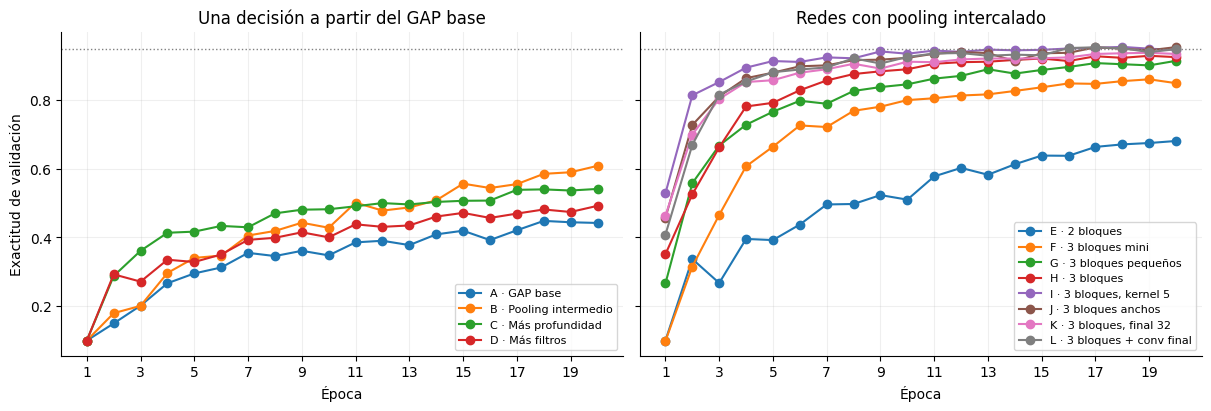

,Decisión que cambia,De → a,Δ parámetros,Validación antes (%),Validación después (%),Δ validación (pp)
0,Ubicación del pooling,A → B,0,44.20,60.87,16.67
1,Profundidad (+1 conv),A → C,2320,44.20,54.13,9.93
2,Filtros (16 → 32),A → D,7248,44.20,49.20,5.00
3,Kernel (3 → 5),H → I,10368,92.60,94.73,2.13
4,Filtros (×2),H → J,17728,92.60,95.53,2.93
5,Filtros última capa (64 → 32),J → K,-9568,95.53,93.53,-2.00
6,Profundidad (+1 conv al final),H → L,9248,92.60,94.93,2.33


In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout="constrained")
grupos = [
    ("Una decisión a partir del GAP base", ["A · GAP base", "B · Pooling intermedio",
                                           "C · Más profundidad", "D · Más filtros"]),
    ("Redes con pooling intercalado", ["E · 2 bloques", "F · 3 bloques mini", "G · 3 bloques pequeños",
                                       "H · 3 bloques", "I · 3 bloques, kernel 5", "J · 3 bloques anchos",
                                       "K · 3 bloques, final 32", "L · 3 bloques + conv final"]),
]
for ax, (titulo, nombres) in zip(ejes, grupos):
    for k, nombre in enumerate(nombres):
        curvas(ax, historiales_gap[nombre], "val_accuracy", nombre, f"C{k % 10}")
    ax.axhline(0.95, color="gray", ls=":", lw=1)
    ax.set(title=titulo, xlabel="Época", xticks=range(1, EPOCAS + 1, 2))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
ejes[0].set_ylabel("Exactitud de validación")
plt.show()

def delta(desde, hacia, decision):
    a = tabla_gap.set_index("Variante").loc[desde]
    b = tabla_gap.set_index("Variante").loc[hacia]
    return {"Decisión que cambia": decision, "De → a": f"{desde[0]} → {hacia[0]}",
            "Δ parámetros": int(b["Parámetros entrenables"] - a["Parámetros entrenables"]),
            "Validación antes (%)": a["Exactitud validación (%)"],
            "Validación después (%)": b["Exactitud validación (%)"],
            "Δ validación (pp)": b["Exactitud validación (%)"] - a["Exactitud validación (%)"]}

display(pd.DataFrame([
    delta("A · GAP base", "B · Pooling intermedio", "Ubicación del pooling"),
    delta("A · GAP base", "C · Más profundidad", "Profundidad (+1 conv)"),
    delta("A · GAP base", "D · Más filtros", "Filtros (16 → 32)"),
    delta("H · 3 bloques", "I · 3 bloques, kernel 5", "Kernel (3 → 5)"),
    delta("H · 3 bloques", "J · 3 bloques anchos", "Filtros (×2)"),
    delta("J · 3 bloques anchos", "K · 3 bloques, final 32", "Filtros última capa (64 → 32)"),
    delta("H · 3 bloques", "L · 3 bloques + conv final", "Profundidad (+1 conv al final)"),
]).round(2))

# Selección

Entre las variantes que superan 95 % en validación y tienen menos parámetros que Flatten, elegimos la de **menos parámetros**. La decisión usa solo validación.

In [8]:
candidatas = tabla_gap[tabla_gap["Cumple (>95 % y < Flatten)"]].sort_values("Parámetros entrenables")
display(candidatas[["Variante", "Arquitectura", "Kernel", "Parámetros entrenables",
                    "Exactitud validación (%)"]].round(2))

SELECCION = candidatas.iloc[0]["Variante"]
modelo_sel = modelos_gap[SELECCION]
p_sel = parametros_entrenables(modelo_sel)
print(f"Seleccionada: {SELECCION}")
print(f"Exactitud de validación: {100 * historiales_gap[SELECCION]['val_accuracy'][-1]:.2f} %")
print(f"Parámetros: {p_sel:,} frente a {LIMITE_PARAMETROS:,} de Flatten → "
      f"ahorro de {LIMITE_PARAMETROS - p_sel:,} parámetros "
      f"({100 * (1 - p_sel / LIMITE_PARAMETROS):.1f} % menos; Flatten es {LIMITE_PARAMETROS / p_sel:.1f} veces más grande)")
modelo_sel.summary()

,Variante,Arquitectura,Kernel,Parámetros entrenables,Exactitud validación (%)
9,J · 3 bloques anchos,16-P-32-P-64-P,3,23946,95.53


Seleccionada: J · 3 bloques anchos
Exactitud de validación: 95.53 %
Parámetros: 23,946 frente a 54,330 de Flatten → ahorro de 30,384 parámetros (55.9 % menos; Flatten es 2.3 veces más grande)


Model: "cnn_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 36, 36, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 18, 18, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 18, 18, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 9, 9, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 9, 9, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector (GlobalAveragePooling2D) │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,840 (280.63 KB)

 Trainable params: 23,946 (93.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 47,894 (187.09 KB)

# Efecto del desplazamiento

Comparamos Flatten base, GAP base y el GAP seleccionado sobre las mismas 2 000 imágenes de prueba, sin reentrenar. Usamos la función desplazar del notebook de clase. A 2 y 4 píxeles, la exactitud es el promedio de los desplazamientos hacia arriba, abajo, izquierda y derecha. La caída se reporta como Acc(0 px) − Acc(4 px), en puntos porcentuales.

,Parámetros,0 px (%),2 px (%),4 px (%),Caída Acc(0px) − Acc(4px) (pp),Conserva a 4 px (% de su Acc 0 px)
Modelo,,,,,,
CNN + Flatten (base),54330,97.05,82.72,37.30,59.75,38.43
CNN + GAP (base),2650,46.20,46.21,46.21,-0.01,100.03
GAP seleccionado (J · 3 bloques anchos),23946,95.95,87.98,72.61,23.34,75.68


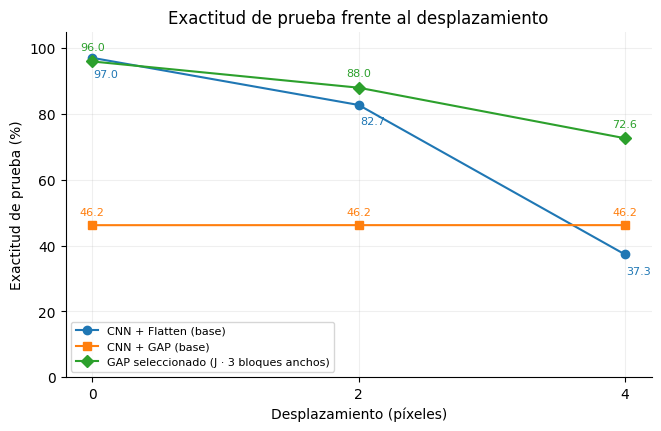

GAP seleccionado − Flatten a 0 px: -1.10 pp
GAP seleccionado − Flatten a 2 px: +5.25 pp
GAP seleccionado − Flatten a 4 px: +35.31 pp


In [ ]:
modelos_desp = {
    "CNN + Flatten (base)": modelo_cnn,
    "CNN + GAP (base)": modelo_gap,
    f"GAP seleccionado ({SELECCION})": modelo_sel,
}
distancias = (0, 2, 4)
tabla_desp = pd.DataFrame(
    {f"{d} px (%)": [exactitud_desplazada(m, d) for m in modelos_desp.values()] for d in distancias},
    index=pd.Index(list(modelos_desp), name="Modelo"),
)
tabla_desp.insert(0, "Parámetros", [parametros_entrenables(m) for m in modelos_desp.values()])
tabla_desp["Caída Acc(0px) − Acc(4px) (pp)"] = tabla_desp["0 px (%)"] - tabla_desp["4 px (%)"]
tabla_desp["Conserva a 4 px (% de su Acc 0 px)"] = 100 * tabla_desp["4 px (%)"] / tabla_desp["0 px (%)"]
display(tabla_desp.round(2))

fig, ax = plt.subplots(figsize=(6.5, 4.2), layout="constrained")
desfases = ((10, -14), (0, 7), (0, 8)) 
for (nombre, fila), color, marca, desfase in zip(tabla_desp.iterrows(), ("C0", "C1", "C2"),
                                                ("o", "s", "D"), desfases):
    valores = [fila[f"{d} px (%)"] for d in distancias]
    ax.plot(distancias, valores, marker=marca, color=color, label=nombre)
    for d, v in zip(distancias, valores):
        ax.annotate(f"{v:.1f}", (d, v), textcoords="offset points", xytext=desfase,
                    ha="center", fontsize=8, color=color)
ax.set(title="Exactitud de prueba frente al desplazamiento", xlabel="Desplazamiento (píxeles)",
       ylabel="Exactitud de prueba (%)", xticks=distancias, ylim=(0, 105))
ax.grid(alpha=0.2)
ax.legend(fontsize=8, loc="lower left")
plt.show()

dif = tabla_desp.iloc[2] - tabla_desp.iloc[0]
for d in distancias:
    print(f"GAP seleccionado − Flatten a {d} px: {dif[f'{d} px (%)']:+.2f} pp")

# Conclusión

Arquitectura seleccionada. J · 16-P-32-P-64-P: tres bloques convolución 3 × 3 (same, ReLU) + max pooling 2 × 2, con 16, 32 y 64 filtros, seguidos de GAP y Dense(10). Los mapas pasan de 36 × 36 a 18 × 18, 9 × 9 y 4 × 4. El campo receptivo final es de 22 píxeles, casi todo el dígito. Fue la única de las doce variantes que superó 95 % en validación (95.53 %), así que también es la de menos parámetros entre las que cumplen. Supera el umbral por poco: L (conv extra, 94.93 %) e I (kernel 5, 94.73 %) quedaron a menos de 1 pp. Con otra semilla el orden entre ellas podría cambiar.

**¿Cuál fue el cambio más importante para superar 95 %?** **Intercalar pooling entre las convoluciones** para que el campo receptivo cubra el dígito antes de promediar. Las comparaciones de una sola decisión lo muestran:

- Mover el pooling entre las dos convoluciones subió la validación +16.7 pp (44.2 → 60.9 %) sin añadir un solo parámetro. Añadir una convolución (+9.9 pp) o duplicar los filtros (+5.0 pp) ayudó menos y costó parámetros.
- Con tres bloques conv + pool, incluso la red F, de 1 674 parámetros (menos que el GAP base), llega a 85.0 %. El GAP base, con campo receptivo de 6 px, se queda en 44.2 %.
- Una vez cubierto el dígito, el último tramo hasta 95 % lo dio la capacidad: más filtros (+2.9 pp) o kernels de 5 × 5 (+2.1 pp). Bajar la última capa de J a 32 filtros costó −2.0 pp y dejó la red por debajo del umbral.

La lección: con GAP, la cabeza ya no puede leer dónde está cada rasgo. Por eso los canales deben codificar la forma completa del dígito antes de promediar, y eso requiere profundidad con reducción espacial.

**¿Cuántos parámetros ahorré frente a Flatten?** 54 330 − 23 946 = 30 384 parámetros menos (55.9 %). Flatten es 2.3 veces más grande. Además, la capa densa de J tiene 650 pesos, frente a los 51 850 de la capa densa de Flatten.

**¿Reconoce mejor los dígitos desplazados que Flatten? ¿Desde qué distancia?** Sí. En prueba:

| Modelo | 0 px | 2 px | 4 px | Caída 0→4 px | Conserva a 4 px |
|---|---|---|---|---|---|
| CNN + Flatten | 97.05 % | 82.72 % | 37.30 % | 59.75 pp | 38 % |
| CNN + GAP base | 46.20 % | 46.21 % | 46.21 % | −0.01 pp | 100 % |
| GAP seleccionado (J) | 95.95 % | 87.98 % | 72.61 % | 23.34 pp | 76 % |

- **A 0 px**, Flatten es 1.1 pp mejor. Con los dígitos centrados no hay ventaja del GAP.
- **A partir de 2 px** el GAP seleccionado ya supera a Flatten por +5.3 pp. A 4 px la diferencia es de +35.3 pp (72.6 % frente a 37.3 %), y su caída es menos de la mitad (23.3 frente a 59.8 pp).
- El GAP base prácticamente no cae (0.01 pp), pero solo porque nunca aprendió bien: a 4 px conserva 46 %, muy por debajo del 73 % del GAP seleccionado. Una caída pequeña no sirve de mucho si la exactitud inicial es baja. Lo útil es clasificar bien y conservar buena parte al desplazar, y eso solo lo logra J.
- J no es totalmente invariante. Los tres max pooling hacen que un desplazamiento de 4 px no corresponda a un desplazamiento exacto de los mapas de 4 × 4, y el padding hace que los bordes respondan distinto. Aun así, GAP elimina la dependencia de la posición que Flatten fija en sus pesos.

# Declaración de uso de la IA

Para esta práctica se utilizó la inteligencia artificial Anthropic Claude como herramienta de asistencia para la revisión, edición y mejora del formato de texto así como el apoyo en la toma de sugerencias para la parte del código y la corrección de errores.